# kNN classifier using sklearn digts dataset

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

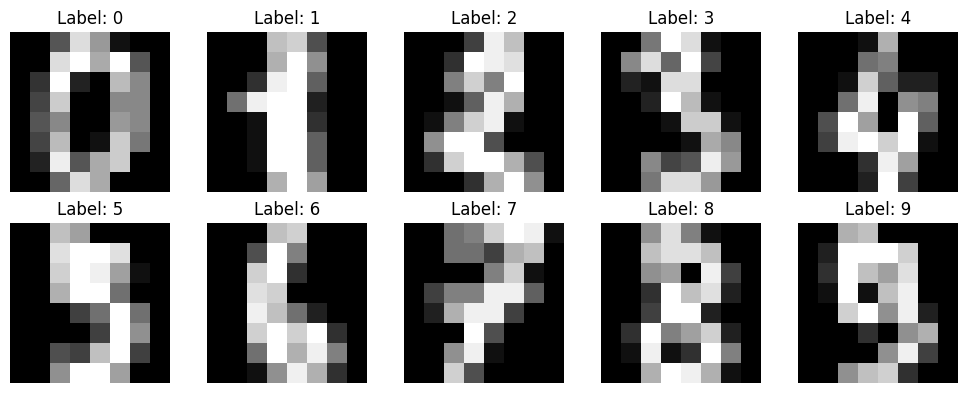

In [11]:
X, y = load_digits(return_X_y=True)

# Split data into train and test sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(digits.images[i], cmap='gray')
    plt.title(f'Label: {y[i]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

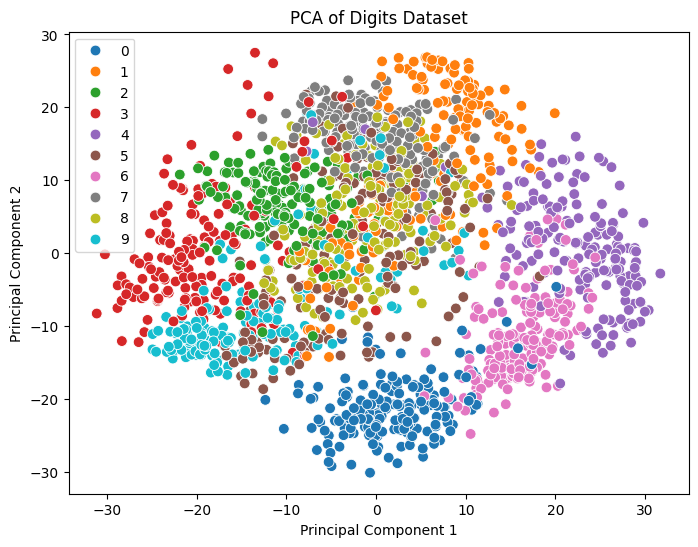

In [3]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette='tab10', s=60)
plt.title('PCA of Digits Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

In [25]:
# Different values of k to test
k_values = [3, 5, 7, 9]
accuracies_knn = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred_knn = knn.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred_knn)
    accuracies_knn.append(accuracy)
    print(f'Accuracy for k={k}: {accuracy:.4f}')

Accuracy for k=3: 0.9694
Accuracy for k=5: 0.9750
Accuracy for k=7: 0.9722
Accuracy for k=9: 0.9722


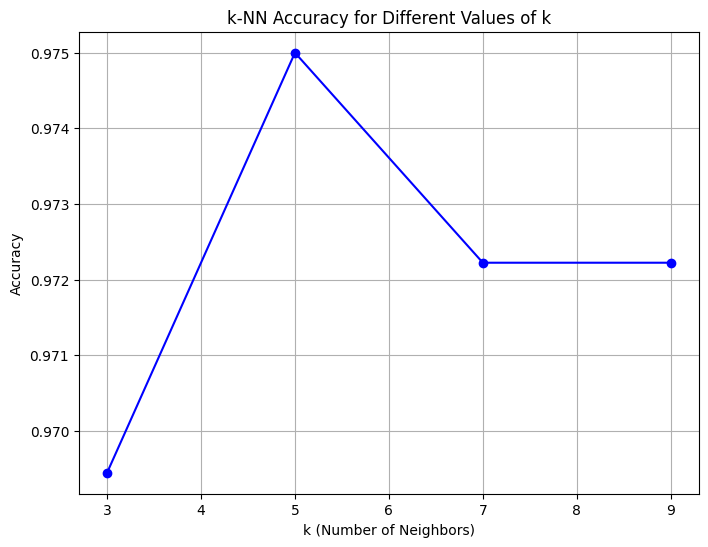

In [26]:
# Plotting the accuracy for different k values
plt.figure(figsize=(8, 6))
plt.plot(k_values, accuracies_knn, marker='o', linestyle='-', color='b')
plt.title('k-NN Accuracy for Different Values of k')
plt.xlabel('k (Number of Neighbors)')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

In [27]:
# Train and evaluate SVM
svm = SVC()
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)
accuracy_svm = accuracy_score(y_test, y_pred_svm)

In [28]:
# Train and evaluate Decision Tree
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
accuracy_dt = accuracy_score(y_test, y_pred_dt)

In [29]:
print(f'k-NN Accuracy (no scaling): {accuracy_knn:.4f}')
print(f'SVM Accuracy (no scaling): {accuracy_svm:.4f}')
print(f'Decision Tree Accuracy (no scaling): {accuracy_dt:.4f}')

k-NN Accuracy (no scaling): 0.9861
SVM Accuracy (no scaling): 0.9806
Decision Tree Accuracy (no scaling): 0.8556


In [30]:
# Apply scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [32]:
# Train and evaluate k-NN with scaling and k=5
knn_scaled = KNeighborsClassifier(n_neighbors=5)
knn_scaled.fit(X_train_scaled, y_train)
y_pred_knn_scaled = knn_scaled.predict(X_test_scaled)
accuracy_knn_scaled = accuracy_score(y_test, y_pred_knn_scaled)

In [33]:
# Train and evaluate SVM with scaling
svm_scaled = SVC()
svm_scaled.fit(X_train_scaled, y_train)
y_pred_svm_scaled = svm_scaled.predict(X_test_scaled)
accuracy_svm_scaled = accuracy_score(y_test, y_pred_svm_scaled)

In [34]:
# Train and evaluate Decision Tree with scaling
dt_scaled = DecisionTreeClassifier()
dt_scaled.fit(X_train_scaled, y_train)
y_pred_dt_scaled = dt_scaled.predict(X_test_scaled)
accuracy_dt_scaled = accuracy_score(y_test, y_pred_dt_scaled)

In [35]:
# Print accuracies with scaling
print(f'k-NN Accuracy (with scaling): {accuracy_knn_scaled:.4f}')
print(f'SVM Accuracy (with scaling): {accuracy_svm_scaled:.4f}')
print(f'Decision Tree Accuracy (with scaling): {accuracy_dt_scaled:.4f}')

k-NN Accuracy (with scaling): 0.9750
SVM Accuracy (with scaling): 0.9806
Decision Tree Accuracy (with scaling): 0.8500


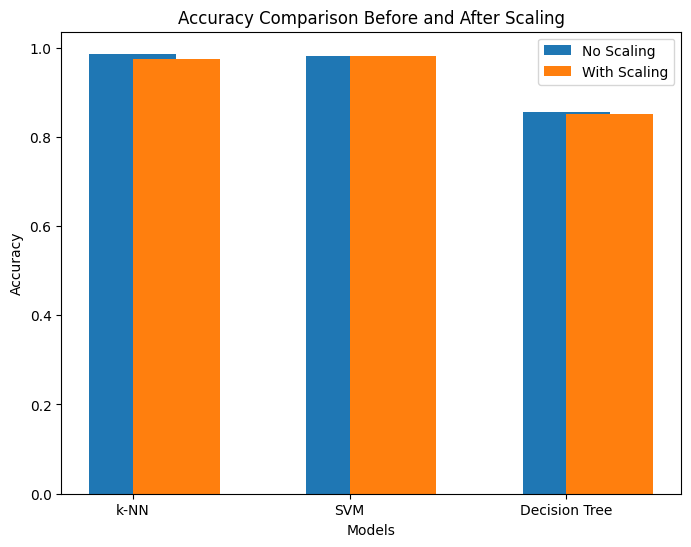

In [36]:
models = ['k-NN', 'SVM', 'Decision Tree']
accuracy_no_scaling = [accuracy_knn, accuracy_svm, accuracy_dt]
accuracy_with_scaling = [accuracy_knn_scaled, accuracy_svm_scaled, accuracy_dt_scaled]

plt.figure(figsize=(8, 6))
plt.bar(models, accuracy_no_scaling, width=0.4, label='No Scaling', align='center')
plt.bar(models, accuracy_with_scaling, width=0.4, label='With Scaling', align='edge')
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.title('Accuracy Comparison Before and After Scaling')
plt.legend()
plt.show()